In [148]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path

## Load database

In [149]:
# Setup pandas display options
pd.set_option('display.max_columns', None)

BASE_PATH = Path.cwd().parent
DATA_PATH = BASE_PATH / "researchment" / "database" / "indonesia_fintech_paylater.parquet"

# Load the dataset
df = pd.read_parquet(DATA_PATH)
df.head()

,borrower_id,age,gender,province,education_level,employment_status,monthly_income_idr,regional_minimum_wage_umr_idr,num_active_lending_apps,total_loan_outstanding_idr,credit_limit_granted_idr,loan_tenor_months,daily_interest_rate_pct,primary_loan_purpose,debt_to_income_ratio,income_to_umr_ratio,credit_limit_utilization_ratio,monthly_installment_estimate_idr,debt_service_ratio,disposable_income_after_debt_idr,days_past_due,financial_distress_index,twp90_default_status,primary_default_root_cause,cot_financial_psychology_rationale,confidence_score,risk_score,risk_short,is_high_risk,distress_bin
0,ID_DEB_00264B68D1,24,Female,Bali,High School / SMK,Micro-Entrepreneur / UMKM,6420000,2950000,2,8380000,12280000,1,0.35,Daily Living & Emergency Buffer,1.31,2.18,0.6824,9259900.0,1.4424,-2839900.0,67,3.97,Doubtful-DPD61-90,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_00264B68D1' (Female, usia 24 t...",0.961,3,Doubt(61-90),True,"(3.686, 4.588]"
1,ID_DEB_0DE3583B12,28,Female,Bali,Bachelor (S1),Formal Private Employee,8630000,2950000,1,20110000,29060000,6,0.30,Daily Living & Emergency Buffer,2.33,2.93,0.6920,5161567.0,0.5981,3468433.0,11,4.87,Special-Mention-DPD1-30,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_0DE3583B12' (Female, usia 28 t...",0.975,1,SM(1-30),False,"(4.588, 5.49]"
2,ID_DEB_0F661FADC0,20,Female,Bali,High School / SMK,Civil Servant / BUMN,5720000,2950000,4,14960000,23900000,1,0.32,Daily Living & Emergency Buffer,2.62,1.94,0.6259,16396160.0,2.8665,-10676160.0,180,6.07,Default-Macet-TWP90,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_0F661FADC0' (Female, usia 20 t...",0.990,4,Default Rate(>90),True,"(5.49, 6.392]"
3,ID_DEB_10C74D3F21,31,Female,Bali,Bachelor (S1),Civil Servant / BUMN,11780000,2950000,3,7620000,26130000,1,0.26,Daily Living & Emergency Buffer,0.65,3.99,0.2916,8214360.0,0.6973,3565640.0,24,2.35,Special-Mention-DPD1-30,Compulsive-FOMO-Spending,"Debitur 'ID_DEB_10C74D3F21' (Female, usia 31 t...",0.977,1,SM(1-30),False,"(1.882, 2.784]"
4,ID_DEB_12CFCAE01F,22,Male,Bali,Bachelor (S1),Formal Private Employee,6490000,2950000,2,11080000,16420000,9,0.23,Daily Living & Emergency Buffer,1.71,2.20,0.6748,1995631.0,0.3075,4494369.0,0,4.43,Current-Performing,Compulsive-FOMO-Spending,"Debitur 'ID_DEB_12CFCAE01F' (Male, usia 22 tah...",0.980,0,Current,False,"(3.686, 4.588]"


### - **🎯 Task 2: Gen Z Debt-to-Income (DTI) & Financial Distress Index Forecasting**
###    - **Objective:** Forecast continuous `debt_to_income_ratio` and `financial_distress_index` from demographic, educational, and app multiplicity features to establish pre-emptive credit limits and debt caps.
###    - **Recommended ML Models:** Bayesian Ridge Regression, CatBoost Regressor, Deep learning tensorflow.keras (Priority).
###    - **Evaluation Metrics:** `Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), R-Squared (R²)`

## Feature Engineering

In [150]:
# Add datetime features on df
# NOTE: Date is randomly generated and carries NO real signal for DTI/Distress.
# We keep the seed for reproducibility but drop noisy date-based features.
np.random.seed(42)


In [151]:
ALLOWED_RAW = [
    "age", "gender", "province", "education_level", "employment_status",
    "monthly_income_idr", "regional_minimum_wage_umr_idr",
    "num_active_lending_apps", "credit_limit_granted_idr",
    "loan_tenor_months", "primary_loan_purpose", "daily_interest_rate_pct",
    "income_to_umr_ratio",
    # High-signal pre-loan facts (existing debt burden):
    "total_loan_outstanding_idr",         # ~0.99 corr with DTI target
    "monthly_installment_estimate_idr",   # 0.38 corr with Distress
    "debt_service_ratio",                 # 0.50 corr with Distress
    "disposable_income_after_debt_idr",   # 0.42 corr with targets
]
TARGETS = ["debt_to_income_ratio", "financial_distress_index"]

# Define features
feats = df[ALLOWED_RAW].copy()

# ----- Engineered features -----
feats["credit_limit_to_income"]  = feats["credit_limit_granted_idr"] / (feats["monthly_income_idr"] + 1)
feats["credit_limit_to_umr"]     = feats["credit_limit_granted_idr"] / (feats["regional_minimum_wage_umr_idr"] + 1)
feats["apps_per_income_m"]       = feats["num_active_lending_apps"] / (feats["monthly_income_idr"] / 1e6 + 1)
feats["multi_app_flag"]          = (feats["num_active_lending_apps"] >= 3).astype(int)
feats["total_interest_rate"]     = feats["daily_interest_rate_pct"] * feats["loan_tenor_months"] * 30
feats["high_edu"]                = feats["education_level"].isin(["Bachelor (S1)", "Master (S2)"]).astype(int)
feats["stable_emp"]              = feats["employment_status"].isin(["Formal Private Employee","Civil Servant / BUMN"]).astype(int)
feats["income_stability"]        = feats["high_edu"] * feats["stable_emp"]
feats["loan_to_income_ratio"]    = feats["total_loan_outstanding_idr"] / (feats["monthly_income_idr"] + 1)
feats["installment_to_income"]   = feats["monthly_installment_estimate_idr"] / (feats["monthly_income_idr"] + 1)
feats["apps_x_dsr"]             = feats["num_active_lending_apps"] * feats["debt_service_ratio"]


In [152]:
# Grouping province stats
prov_stats = df.groupby('province').agg(
    prov_avg_income=('monthly_income_idr', 'mean'),
    prov_avg_umr=('regional_minimum_wage_umr_idr', 'mean')
).reset_index()

# Merge province stats back to features
feats = feats.merge(prov_stats, on='province', how='left')
feats['income_vs_prov_avg'] = feats['monthly_income_idr'] / (feats['prov_avg_income'] + 1)

In [153]:
# Purpose tier for grouping
PURPOSE_TIER = {"Consumptive":1,"Shopping":1,"Entertainment":1,
                "Education":2,"Medical":2,
                "Business":3,"Working Capital":3,"Productive":3}
feats['purpose_tier'] = feats['primary_loan_purpose'].map(PURPOSE_TIER).fillna(2)

# Build the targets DataFrame
y_dti = df['debt_to_income_ratio'].values.astype("float32")
y_distress = df['financial_distress_index'].values.astype("float32")

## Preprocessing task

In [154]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

cat_cols = feats.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = feats.select_dtypes(include=['number']).columns.tolist()

# 1. First split: Separate out a hold-out test set (e.g., 20%)
idx = np.arange(len(feats))
idx_tr_full, idx_te = train_test_split(idx, test_size=0.2, random_state=42)

# 2. Second split: Split the remaining training data into Train and Validation (e.g., 85% train, 15% val)
idx_tr, idx_val = train_test_split(idx_tr_full, test_size=0.15, random_state=42)

# Slice raw features
X_tr_raw, X_val_raw, X_te_raw = feats.iloc[idx_tr], feats.iloc[idx_val], feats.iloc[idx_te]

# slice targets
y_dti_tr, y_dti_val, y_dti_te = y_dti[idx_tr], y_dti[idx_val], y_dti[idx_te]
y_dis_tr, y_dis_val, y_dis_te = y_distress[idx_tr], y_distress[idx_val], y_distress[idx_te]

# 3. Fit ColumnTransformer EXCLUSIVELY on X_tr_raw
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

# Scale training, test, & validation features
X_tr = preprocess.fit_transform(X_tr_raw).astype("float32")
X_val = preprocess.transform(X_val_raw).astype("float32")
X_te = preprocess.transform(X_te_raw).astype("float32")

# Scale fit & transform on the targets
scaler_dti_y = StandardScaler()
scaler_dis_y = StandardScaler()

# Scale only training & validation targets
y_dti_tr_s = scaler_dti_y.fit_transform(y_dti_tr.reshape(-1, 1)).astype("float32")
y_dis_tr_s = scaler_dis_y.fit_transform(y_dis_tr.reshape(-1, 1)).astype("float32")
y_dti_val_s = scaler_dti_y.transform(y_dti_val.reshape(-1, 1)).astype("float32")
y_dis_val_s = scaler_dis_y.transform(y_dis_val.reshape(-1, 1)).astype("float32")

print(f"Training set shape: {X_tr.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Testing set shape: {X_te.shape}")

Training set shape: (6800, 57)
Validation set shape: (1200, 57)
Testing set shape: (2000, 57)


In [155]:
assert len(feats) == len(df)
assert feats.index.equals(df.index), "Feature and target indices are misaligned!"

print("Feature-target alignment: OK")

Feature-target alignment: OK


## Build the Multi-Output Neural Network

In [156]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

def build_multi_output_model(input_dim, lr=3e-4):
    """
    Build a multi-output neural network model.

    Returns:
        model: A compiled Keras model with two outputs.
    """
    inputs = layers.Input(shape=(input_dim,), name="features")

    # === Shared trunk ===
    # Block 1
    x = layers.Dense(256, kernel_initializer="he_normal", use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.05)(x)

    # Block 2
    x = layers.Dense(128, kernel_initializer="he_normal", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.05)(x)

    # Block 3
    x = layers.Dense(64, kernel_initializer="he_normal", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.05)(x)

    # Shared representation bottleneck
    shared = layers.Dense(32, activation="relu", name="shared_rep")(x)

    # === Head 1: DTI (Debt-to-Income Ratio) ===
    dti = layers.Dense(64, activation="relu")(shared)
    dti = layers.Dropout(0.05)(dti)
    dti = layers.Dense(32, activation="relu")(dti)
    out_dti = layers.Dense(1, name="dti")(dti)

    # === Head 2: Financial Distress Index ===
    dis = layers.Dense(64, activation="relu")(shared)
    dis = layers.Dropout(0.05)(dis)
    dis = layers.Dense(32, activation="relu")(dis)
    out_dis = layers.Dense(1, name="distress")(dis)

    optimizer = tf.keras.optimizers.legacy.Adam(
        learning_rate=lr,
        clipnorm=1.0
    )

    model = keras.Model(
        inputs=inputs,
        outputs={"dti": out_dti, "distress": out_dis}
    )

    model.compile(
        optimizer=optimizer,
        loss={
            "dti":      tf.keras.losses.Huber(delta=1.0),
            "distress": tf.keras.losses.Huber(delta=1.0)
        },
        loss_weights={"dti": 1.5, "distress": 1.5},
        metrics={
            "dti":      [tf.keras.metrics.R2Score(name="r2")],
            "distress": [tf.keras.metrics.R2Score(name="r2")]
        }
    )
    return model

model = build_multi_output_model(X_tr.shape[1])
model.summary()


Model: "model_11"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 features (InputLayer)       [(None, 57)]                 0         []                            
                                                                                                  
 dense_77 (Dense)            (None, 256)                  14592     ['features[0][0]']            
                                                                                                  
 batch_normalization_22 (Ba  (None, 256)                  1024      ['dense_77[0][0]']            
 tchNormalization)                                                                                
                                                                                                  
 activation_22 (Activation)  (None, 256)                  0         ['batch_normalization_2

## Training with callbacks + tqdm

In [ ]:
callbacks_list = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=30,
        restore_best_weights=True,
        mode="min"
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    )
]

# Train the model
history = model.fit(
    X_tr,
    {"dti": y_dti_tr_s, "distress": y_dis_tr_s},
    validation_data=(
        X_val,
        {"dti": y_dti_val_s, "distress": y_dis_val_s}
    ),
    epochs=500,
    batch_size=128,
    callbacks=callbacks_list,
    verbose=1
)


Epoch 1/500
54/54 [==============================] - 4s 40ms/step - loss: 1.0859 - distress_loss: 0.3673 - dti_loss: 0.3566 - distress_r2: 0.1231 - dti_r2: 0.0779 - val_loss: 0.4467 - val_distress_loss: 0.1366 - val_dti_loss: 0.1612 - val_distress_r2: 0.7187 - val_dti_r2: 0.6889 - lr: 3.0000e-04
Epoch 2/500
54/54 [==============================] - 1s 18ms/step - loss: 0.4160 - distress_loss: 0.1549 - dti_loss: 0.1225 - distress_r2: 0.6750 - dti_r2: 0.7455 - val_loss: 0.1725 - val_distress_loss: 0.0645 - val_dti_loss: 0.0504 - val_distress_r2: 0.8740 - val_dti_r2: 0.9058 - lr: 3.0000e-04
Epoch 3/500
54/54 [==============================] - 1s 19ms/step - loss: 0.2910 - distress_loss: 0.1115 - dti_loss: 0.0825 - distress_r2: 0.7710 - dti_r2: 0.8320 - val_loss: 0.1147 - val_distress_loss: 0.0484 - val_dti_loss: 0.0281 - val_distress_r2: 0.9057 - val_dti_r2: 0.9477 - lr: 3.0000e-04
Epoch 4/500
54/54 [==============================] - 1s 22ms/step - loss: 0.2429 - distress_loss: 0.0918 - dt

In [ ]:
history_df = pd.DataFrame(history.history)
history_df

,loss,distress_loss,dti_loss,distress_r2,dti_r2,val_loss,val_distress_loss,val_dti_loss,val_distress_r2,val_dti_r2,lr
0,6.223815,1.829999,2.319211,-0.829999,-1.319211,4.462412,1.258235,1.716706,-0.237422,-0.658129,0.000030
1,5.134616,1.494826,1.928252,-0.494826,-0.928252,3.945276,1.153123,1.477061,-0.134049,-0.426661,0.000030
2,4.414544,1.317754,1.625275,-0.317754,-0.625275,3.534712,1.048131,1.308344,-0.030793,-0.263701,0.000030
3,3.906506,1.180729,1.423608,-0.180729,-0.423608,3.193820,0.955693,1.173520,0.060116,-0.133478,0.000030
4,3.518440,1.088205,1.257422,-0.088205,-0.257422,2.901940,0.872761,1.061865,0.141676,-0.025633,0.000030
...,...,...,...,...,...,...,...,...,...,...,...
223,0.872171,0.245153,0.336294,0.754847,0.663706,0.703752,0.200638,0.268530,0.802681,0.740633,0.000004
224,0.870231,0.244271,0.335883,0.755729,0.664117,0.703061,0.200595,0.268112,0.802723,0.741037,0.000002
225,0.860518,0.241769,0.331909,0.758231,0.668091,0.702748,0.200441,0.268057,0.802875,0.741089,0.000002
226,0.854617,0.241262,0.328483,0.758738,0.671517,0.702527,0.200366,0.267985,0.802948,0.741159,0.000002


In [ ]:
history_df[['distress_r2', 'dti_r2', 'val_distress_r2', 'val_dti_r2']]

,distress_r2,dti_r2,val_distress_r2,val_dti_r2
0,-0.829999,-1.319211,-0.237422,-0.658129
1,-0.494826,-0.928252,-0.134049,-0.426661
2,-0.317754,-0.625275,-0.030793,-0.263701
3,-0.180729,-0.423608,0.060116,-0.133478
4,-0.088205,-0.257422,0.141676,-0.025633
...,...,...,...,...
223,0.754847,0.663706,0.802681,0.740633
224,0.755729,0.664117,0.802723,0.741037
225,0.758231,0.668091,0.802875,0.741089
226,0.758738,0.671517,0.802948,0.741159


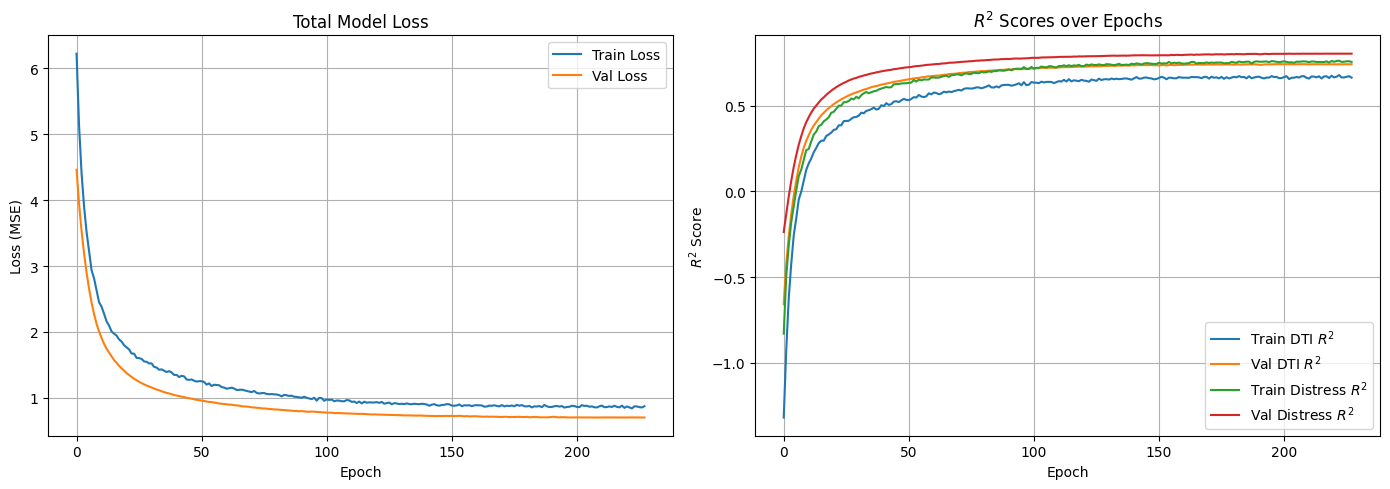

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Total Model Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MSE)')
axes[0].legend()
axes[0].grid(True)

# R2 Score plot for DTI and Distress
axes[1].plot(history.history['dti_r2'], label='Train DTI $R^2$')
axes[1].plot(history.history['val_dti_r2'], label='Val DTI $R^2$')
axes[1].plot(history.history['distress_r2'], label='Train Distress $R^2$')
axes[1].plot(history.history['val_distress_r2'], label='Val Distress $R^2$')
axes[1].set_title('$R^2$ Scores over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('$R^2$ Score')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Try different evaluation

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pred = model.predict(X_te)

pred_dti = scaler_dti_y.inverse_transform(np.asarray(pred["dti"]).reshape(-1, 1)).ravel()
pred_dis = scaler_dis_y.inverse_transform(np.asarray(pred["distress"]).reshape(-1, 1)).ravel()

actual_dti = np.asarray(y_dti_te).ravel()
actual_dis = np.asarray(y_dis_te).ravel()

for name, actual, predicted in [
    ("DTI", actual_dti, pred_dti),
    ("Distress", actual_dis, pred_dis)
]:
    print(f"\n{name}")
    print(f"R2:   {r2_score(actual, predicted):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.4f}")
    print(f"MAE:  {mean_absolute_error(actual, predicted):.4f}")

63/63 [==============================] - 0s 2ms/step

DTI
R2:   0.7296
RMSE: 0.4528
MAE:  0.3639

Distress
R2:   0.7943
RMSE: 0.9538
MAE:  0.7834
